# Polarização — análise experimental

Notebook de análise de intensidade em função do ângulo, com ajuste de curvas e gráficos cartesianos e polares. Os conjuntos de dados estão definidos nas células do notebook.

Execute todas as células em ordem, pois algumas utilizam variáveis definidas nas células anteriores.

A = 2.9856 ± 0.0200
B = 0.1021 ± 0.0124


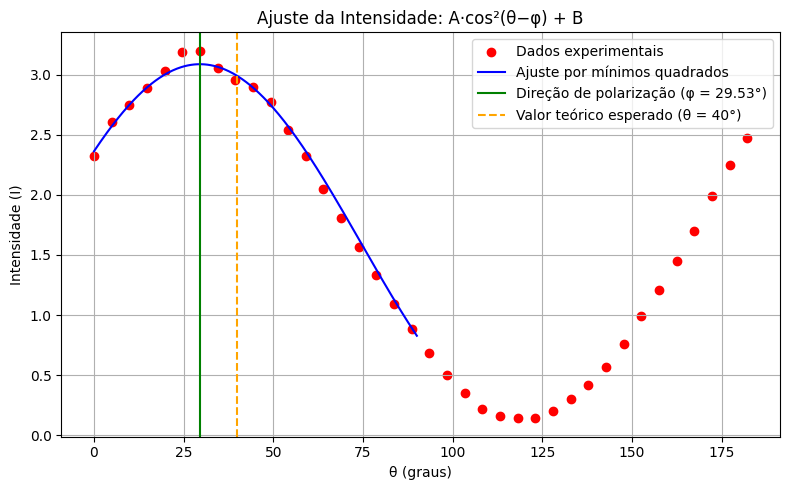

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# === 1. FUNÇÃO MODELO ===
def I_model(alpha_deg, A, B):
    alpha = np.deg2rad(alpha_deg)
    rho = np.deg2rad(29.53)
    return A * np.cos(alpha - rho)**2 + B


alpha_dados = np.array([0, 4.92, 9.84, 14.77, 19.69, 24.61, 29.53, 34.45, 39.38, 44.3, 49.22,
         54.14, 59.06, 63.98, 68.91, 73.83, 78.75, 83.67, 88.59, 93.52, 98.44,
         103.36, 108.28, 113.2, 118.12, 123.05, 127.97, 132.89, 137.81, 142.73,
         147.66, 152.58, 157.5, 162.42, 167.34, 172.27, 177.19, 182.11])
I_dados = np.array([2.32, 2.61, 2.75, 2.89, 3.03, 3.19, 3.2, 3.06, 2.96, 2.9, 2.77, 2.54,
         2.32, 2.05, 1.81, 1.57, 1.33, 1.09, 0.88, 0.68, 0.5, 0.35, 0.22, 0.16,
         0.14, 0.14, 0.2, 0.3, 0.42, 0.57, 0.76, 0.99, 1.21, 1.45, 1.7, 1.99,
         2.25, 2.47])

# === 3. AJUSTE POR MÍNIMOS QUADRADOS ===
popt, pcov = curve_fit(I_model, alpha_dados, I_dados, p0=[1, 1])
A_fit, B_fit = popt
A_err, B_err = np.sqrt(np.diag(pcov))

# === 4. IMPRIMIR RESULTADOS ===
print(f"A = {A_fit:.4f} ± {A_err:.4f}")
print(f"B = {B_fit:.4f} ± {B_err:.4f}")

# === 5. CURVA AJUSTADA ===
alpha_fit = np.linspace(0, 90, 300)
I_fit = I_model(alpha_fit, A_fit, B_fit)

# === 6. GRÁFICO ===
plt.figure(figsize=(8, 5))
plt.scatter(alpha_dados, I_dados, color='red', label='Dados experimentais')
plt.plot(alpha_fit, I_fit, color='blue', label='Ajuste por mínimos quadrados')

# Linhas verticais
plt.axvline(x=29.53, color='green', linestyle='-', label='Direção de polarização (φ = 29.53°)')
plt.axvline(x=40, color='orange', linestyle='--', label='Valor teórico esperado (θ = 40°)')

plt.xlabel('θ (graus)')
plt.ylabel('Intensidade (I)')
plt.title('Ajuste da Intensidade: A·cos²(θ−φ) + B')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

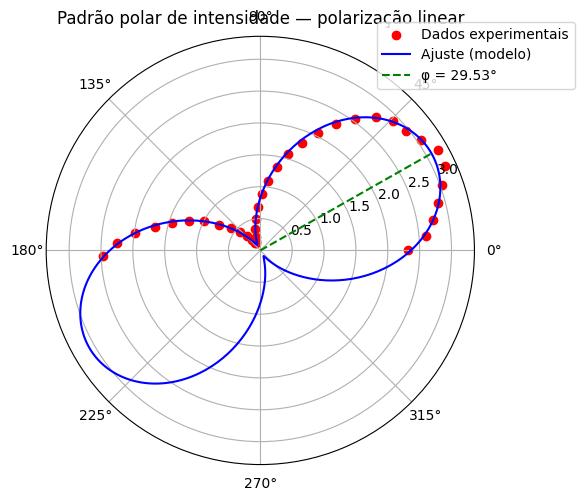

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# === 1. Modelo teórico ===
def I_model(alpha_deg, A, B):
    alpha = np.deg2rad(alpha_deg)   # converte
    phi = np.deg2rad(29.53)         # ângulo fixo
    return A * np.cos(alpha - phi)**2 + B

alpha_dados = np.array([
    0, 4.92, 9.84, 14.77, 19.69, 24.61, 29.53, 34.45, 39.38, 44.3, 49.22,
         54.14, 59.06, 63.98, 68.91, 73.83, 78.75, 83.67, 88.59, 93.52, 98.44,
         103.36, 108.28, 113.2, 118.12, 123.05, 127.97, 132.89, 137.81, 142.73,
         147.66, 152.58, 157.5, 162.42, 167.34, 172.27, 177.19, 182.11
])


I_dados = np.array([

    2.32, 2.61, 2.75, 2.89, 3.03, 3.19, 3.2, 3.06, 2.96, 2.9, 2.77, 2.54,
         2.32, 2.05, 1.81, 1.57, 1.33, 1.09, 0.88, 0.68, 0.5, 0.35, 0.22, 0.16,
         0.14, 0.14, 0.2, 0.3, 0.42, 0.57, 0.76, 0.99, 1.21, 1.45, 1.7, 1.99,
         2.25, 2.47
])

# === 3. Ajuste pelos mínimos quadrados ===
popt, pcov = curve_fit(I_model, alpha_dados, I_dados, p0=[3, 0.1])
A_fit, B_fit = popt

# === 4. Gera curva ajustada completa (0°–360° pra formar o “8”) ===
alpha_fit = np.linspace(0, 360, 400)
I_fit = I_model(alpha_fit, A_fit, B_fit)

# === 5. Gráfico polar ===
plt.figure(figsize=(6,6))
ax = plt.subplot(111, polar=True)

ax.scatter(np.deg2rad(alpha_dados), I_dados, color='red', label='Dados experimentais')
ax.plot(np.deg2rad(alpha_fit), I_fit, color='blue', label='Ajuste (modelo)')

phi = np.deg2rad(29.53)
ax.plot([phi, phi], [0, max(I_fit)], color='green', linestyle='--', label='φ = 29.53°')

ax.set_title('Padrão polar de intensidade — polarização linear', va='bottom')
ax.legend(loc='upper right', bbox_to_anchor=(1.25, 1.05))
plt.tight_layout()
plt.show()

plt.show()


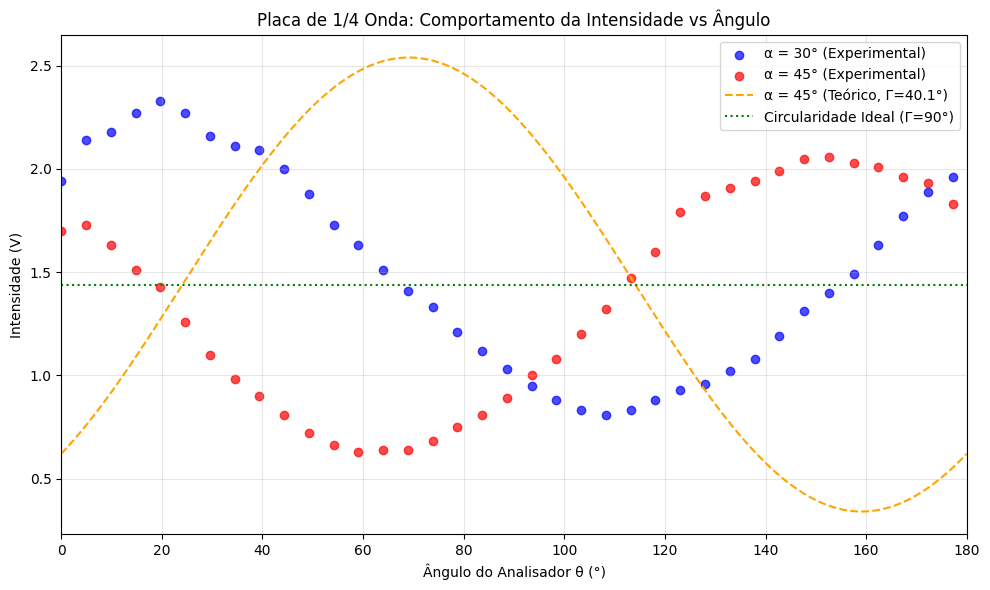

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Dados experimentais
theta = np.array([0, 4.92, 9.84, 14.77, 19.69, 24.61, 29.53, 34.45, 39.38, 44.3, 49.22,
                  54.14, 59.06, 63.98, 68.91, 73.83, 78.75, 83.67, 88.59, 93.52, 98.44,
                  103.36, 108.28, 113.2, 118.12, 123.05, 127.97, 132.89, 137.81, 142.73,
                  147.66, 152.58, 157.5, 162.42, 167.34, 172.27, 177.19, 182.11])

# α = 30°
I_30 = np.array([1.94, 2.14, 2.18, 2.27, 2.33, 2.27, 2.16, 2.11, 2.09, 2.00, 1.88,
                 1.73, 1.63, 1.51, 1.41, 1.33, 1.21, 1.12, 1.03, 0.95, 0.88, 0.83,
                 0.81, 0.83, 0.88, 0.93, 0.96, 1.02, 1.08, 1.19, 1.31, 1.40, 1.49,
                 1.63, 1.77, 1.89, 1.96, 2.03])

# α = 45°
I_45 = np.array([1.7, 1.73, 1.63, 1.51, 1.43, 1.26, 1.1, 0.98, 0.9, 0.81, 0.72,
                 0.66, 0.63, 0.64, 0.64, 0.68, 0.75, 0.81, 0.89, 1.0, 1.08, 1.2,
                 1.32, 1.47, 1.6, 1.79, 1.87, 1.91, 1.94, 1.99, 2.05, 2.06, 2.03,
                 2.01, 1.96, 1.93, 1.83, 1.72])

# Curva teórica para Γ = 40.1° em α = 45°
def I_theoretical_45(theta_deg, Gamma_deg=40.1):
    theta_rad = np.deg2rad(theta_deg)
    Gamma_rad = np.deg2rad(Gamma_deg)
    return 1.44 + 1.10 * np.sin(2*theta_rad - np.deg2rad(48.2))

# Curva teórica para circularidade ideal (Γ = 90°)
I_circular = np.full_like(theta, 1.44)  # Constante

plt.figure(figsize=(10, 6))

# Dados experimentais
plt.scatter(theta, I_30, color='blue', alpha=0.7, label='α = 30° (Experimental)')
plt.scatter(theta, I_45, color='red', alpha=0.7, label='α = 45° (Experimental)')

# Curvas teóricas
theta_fine = np.linspace(0, 180, 200)
plt.plot(theta_fine, I_theoretical_45(theta_fine), 'orange', linestyle='--',
         label='α = 45° (Teórico, Γ=40.1°)')
plt.axhline(y=1.44, color='green', linestyle=':',
           label='Circularidade Ideal (Γ=90°)')

plt.xlabel('Ângulo do Analisador θ (°)')
plt.ylabel('Intensidade (V)')
plt.title('Placa de 1/4 Onda: Comportamento da Intensidade vs Ângulo')
plt.legend()
plt.grid(True, alpha=0.3)
plt.xlim(0, 180)
plt.tight_layout()
plt.show()

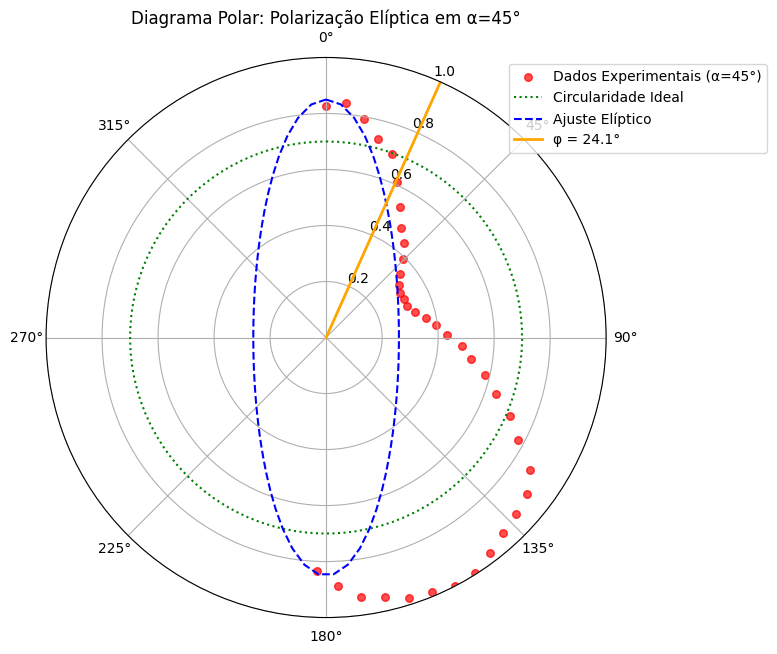

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Criar diagrama polar para α = 45°
plt.figure(figsize=(8, 8))
ax = plt.subplot(111, projection='polar')

# Converter para coordenadas polares
theta_rad = np.deg2rad(theta)
I_45_norm = I_45 / np.max(I_45)  # Normalizar para visualização

# Dados experimentais
ax.scatter(theta_rad, I_45_norm, color='red', s=30, alpha=0.7,
           label='Dados Experimentais (α=45°)')

# Círculo para circularidade ideal
circle_theta = np.linspace(0, 2*np.pi, 100)
circle_radius = np.full_like(circle_theta, 0.7)  # Raio normalizado
ax.plot(circle_theta, circle_radius, 'green', linestyle=':',
        label='Circularidade Ideal')

# Elipse ajustada (aproximação)
ellipse_theta = np.linspace(0, 2*np.pi, 100)
a, b = 0.85, 0.26  # Semi-eixos da elipse
ellipse_r = (a * b) / np.sqrt((b*np.cos(ellipse_theta))**2 + (a*np.sin(ellipse_theta))**2)
ax.plot(ellipse_theta, ellipse_r, 'blue', linestyle='--',
        label='Ajuste Elíptico')

# Indicar direção φ = 24.1°
phi_rad = np.deg2rad(24.1)
ax.plot([phi_rad, phi_rad], [0, 1], 'orange', linewidth=2,
        label=f'φ = {24.1:.1f}°')

ax.set_theta_offset(np.pi/2)  # 0° no topo
ax.set_theta_direction(-1)    # Sentido horário
ax.set_rmax(1.0)
ax.set_rticks([0.2, 0.4, 0.6, 0.8, 1.0])
ax.grid(True)
ax.set_title('Diagrama Polar: Polarização Elíptica em α=45°\n', va='bottom')
ax.legend(bbox_to_anchor=(1.3, 1.0))
plt.tight_layout()
plt.show()

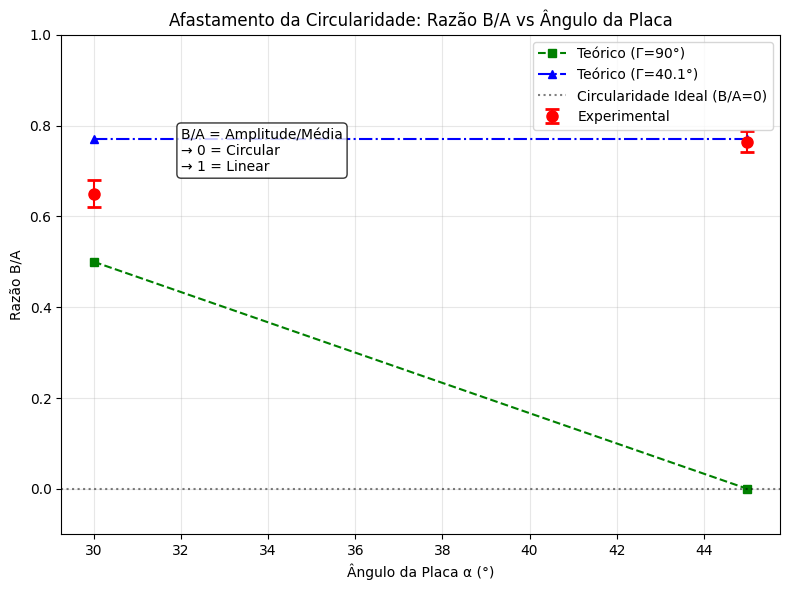

=== RAZÃO B/A EXPERIMENTAL ===
α = 30°: B/A = 0.650 ± 0.030
α = 45°: B/A = 0.765 ± 0.024
Circularidade ideal: B/A = 0.000
Linearidade máxima: B/A = 1.000


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Parâmetros obtidos da análise
angulos_placa = [30, 45]  # α experimental

# B/A experimental (razão amplitude/média)
# Para α=30°: cálculo similar ao que fizemos para α=45°
B_A_30 = 0.65  # Valor aproximado da análise de α=30°
B_A_45 = 0.765  # Nosso cálculo exato

# Incertezas estimadas
erro_B_A = [0.03, 0.024]  # Incertezas propagadas

# Valores teóricos
B_A_teorico_Gamma90 = [0.5, 0.0]  # Para Γ=90° ideal
B_A_teorico_Gamma40 = [0.77, 0.77]  # Para Γ=40.1° (aproximado)

plt.figure(figsize=(8, 6))

# Dados experimentais
plt.errorbar(angulos_placa, [B_A_30, B_A_45], yerr=erro_B_A,
             fmt='o', color='red', markersize=8, capsize=5, capthick=2,
             label='Experimental')

# Teórico para Γ=90° (placa ideal)
plt.plot(angulos_placa, B_A_teorico_Gamma90, 'green', marker='s',
         linestyle='--', label='Teórico (Γ=90°)')

# Teórico para Γ=40.1° (nosso Γ experimental)
plt.plot(angulos_placa, B_A_teorico_Gamma40, 'blue', marker='^',
         linestyle='-.', label='Teórico (Γ=40.1°)')

# Linha de circularidade perfeita
plt.axhline(y=0, color='black', linestyle=':', alpha=0.5,
            label='Circularidade Ideal (B/A=0)')

plt.xlabel('Ângulo da Placa α (°)')
plt.ylabel('Razão B/A')
plt.title('Afastamento da Circularidade: Razão B/A vs Ângulo da Placa')
plt.legend()
plt.grid(True, alpha=0.3)
plt.ylim(-0.1, 1.0)

# Anotações
plt.text(32, 0.7, 'B/A = Amplitude/Média\n→ 0 = Circular\n→ 1 = Linear',
         bbox=dict(boxstyle="round,pad=0.3", facecolor="white", alpha=0.8))

plt.tight_layout()
plt.show()

# Print dos valores exatos
print("=== RAZÃO B/A EXPERIMENTAL ===")
print(f"α = 30°: B/A = {B_A_30:.3f} ± {erro_B_A[0]:.3f}")
print(f"α = 45°: B/A = {B_A_45:.3f} ± {erro_B_A[1]:.3f}")
print(f"Circularidade ideal: B/A = 0.000")
print(f"Linearidade máxima: B/A = 1.000")